# Church giving and attendance analysis

This notebook analyses the data exported from the **Church Management System** (Reports page, CSV buttons). It uses the fictional demo data, so every number is made up, but the method works on a real export.

**What it answers**
1. How has giving changed month by month?
2. Who gives, and how many members give regularly?
3. What does the trend suggest for next month?
4. How well attended are our services, and by which groups?

**To run it:** `pip install -r requirements.txt`, then open this notebook in VS Code or Jupyter. The three CSV files are in `data/`. To analyse your own data, download fresh CSVs from the app's Reports page and replace them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams.update({
    'figure.figsize': (9, 4),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
})

## Load the data

The app writes CSVs with a byte-order mark (so Excel shows accents correctly), hence `utf-8-sig`.

In [2]:
members = pd.read_csv('data/members.csv', encoding='utf-8-sig', parse_dates=['joined', 'birth_date'])
donations = pd.read_csv('data/donations.csv', encoding='utf-8-sig', parse_dates=['date'])
attendance = pd.read_csv('data/attendance.csv', encoding='utf-8-sig', parse_dates=['event_date'])

print(f'{len(members)} members, {len(donations)} donations, {len(attendance)} attendance records')
print(f"Donations run from {donations['date'].min():%d %b %Y} to {donations['date'].max():%d %b %Y}")
donations.head()

24 members, 98 donations, 115 attendance records
Donations run from 04 Nov 2025 to 20 Oct 2026


,id,date,donation_type,amount,member_id,member_name,notes
0,3,2025-11-04,Tithes,"1,000.00",7.00,Keabetswe Modise,NaN
1,1,2025-11-06,Tithes,600.00,13.00,Atang Mokgosi,NaN
2,2,2025-11-14,Tithes,"1,150.00",5.00,Goitseone Molefe,NaN
3,4,2025-11-14,Tithes,"1,300.00",19.00,Omphile Tau,NaN
4,5,2025-11-24,Tithes,"1,350.00",3.00,Resego Molefe,NaN


## 1. Giving over time

Total given each month, split into tithes and other givings.

In [3]:
monthly = (
    donations.assign(month=donations['date'].dt.to_period('M'))
    .pivot_table(index='month', columns='donation_type', values='amount', aggfunc='sum', fill_value=0)
)
monthly['Total'] = monthly.sum(axis=1)
monthly.tail(12)

donation_type,Other Givings,Tithes,Total
month,,,
2025-11,0.00,"6,650.00","6,650.00"
2025-12,285.00,"4,070.00","4,355.00"
2026-01,"1,345.00","4,820.00","6,165.00"
2026-02,705.00,"8,060.00","8,765.00"
2026-03,"1,120.00","5,540.00","6,660.00"
2026-04,780.00,"2,525.00","3,305.00"
2026-05,535.00,"8,025.00","8,560.00"
2026-06,270.00,"7,745.00","8,015.00"
2026-07,"1,365.00","9,175.00","10,540.00"


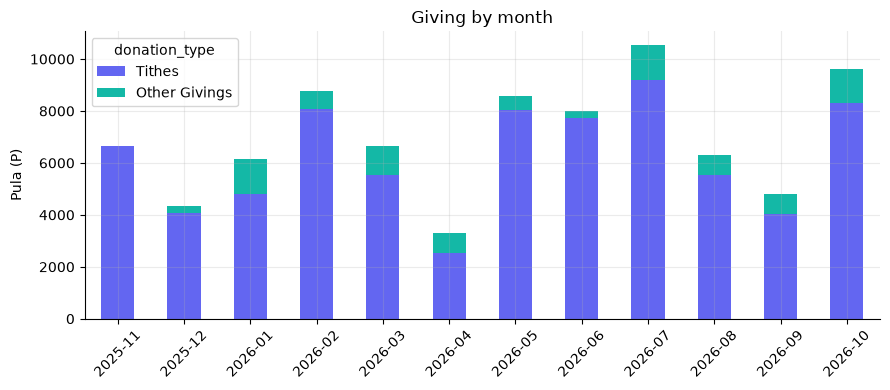

In [4]:
ax = monthly[['Tithes', 'Other Givings']].plot(kind='bar', stacked=True, color=['#6366f1', '#14b8a6'])
ax.set_title('Giving by month')
ax.set_xlabel('')
ax.set_ylabel('Pula (P)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Who gives?

Top givers, how many members give at all, and how many give **regularly** (in 3 or more different months, the same definition the Reports page uses).

In [5]:
named = donations.dropna(subset=['member_id']).assign(member_id=lambda d: d['member_id'].astype(int))

by_member = (
    named.groupby(['member_id', 'member_name'])
    .agg(total=('amount', 'sum'),
         gifts=('amount', 'size'),
         months=('date', lambda s: s.dt.to_period('M').nunique()))
    .sort_values('total', ascending=False)
    .reset_index()
)
by_member['share_%'] = (by_member['total'] / donations['amount'].sum() * 100).round(1)
by_member.head(10)

,member_id,member_name,total,gifts,months,share_%
0,13,Atang Mokgosi,"7,660.00",7,7,9.10
1,7,Keabetswe Modise,"5,930.00",6,4,7.10
2,8,Naledi Sebego,"5,910.00",6,3,7.10
3,1,Tshepo Ntsima,"5,865.00",7,6,7.00
4,19,Omphile Tau,"5,650.00",6,4,6.70
5,9,Boitumelo Kgosi,"5,340.00",5,5,6.40
6,21,Dineo Modise,"5,095.00",7,6,6.10
7,24,Onalenna Kgosi,"4,475.00",5,5,5.30
8,6,Lorato Moeng,"4,185.00",5,3,5.00
9,2,Gorata Mokgosi,"3,590.00",4,3,4.30


18 of 24 members gave at least once.
13 members gave in 3 or more different months (regular givers).
16% of the money came from gifts with no member recorded.


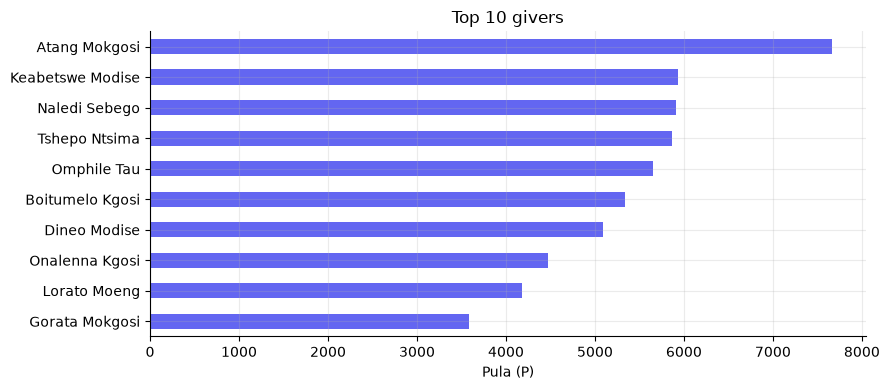

In [6]:
regular = int((by_member['months'] >= 3).sum())
anonymous_share = donations.loc[donations['member_id'].isna(), 'amount'].sum() / donations['amount'].sum() * 100

print(f'{len(by_member)} of {len(members)} members gave at least once.')
print(f'{regular} members gave in 3 or more different months (regular givers).')
print(f'{anonymous_share:.0f}% of the money came from gifts with no member recorded.')

top = by_member.head(10).iloc[::-1]
ax = top.plot(kind='barh', x='member_name', y='total', color='#6366f1', legend=False)
ax.set_title('Top 10 givers')
ax.set_xlabel('Pula (P)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 3. Trend and projection

A straight line fitted to the last 12 months (ordinary least squares). The dashboard's "Projected next month" uses the same method.

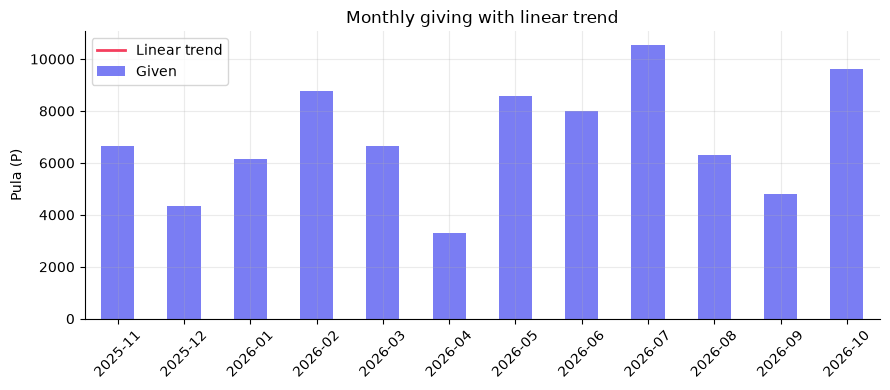

Trend: +196 pula per month
Projected total for next month: P 8,251


In [7]:
series = monthly['Total'].tail(12)
x = np.arange(len(series))
slope, intercept = np.polyfit(x, series.values, 1)
trend = intercept + slope * x
next_month = max(0.0, intercept + slope * len(series))

ax = series.plot(kind='bar', color='#6366f1', alpha=0.85, label='Given')
ax.plot(x, trend, color='#f43f5e', linewidth=2, label='Linear trend')
ax.set_title('Monthly giving with linear trend')
ax.set_xlabel('')
ax.set_ylabel('Pula (P)')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f'Trend: {slope:+,.0f} pula per month')
print(f'Projected total for next month: P {next_month:,.0f}')

## 4. Attendance

Attendance at Sunday services over time, and the attendance rate for each member category.

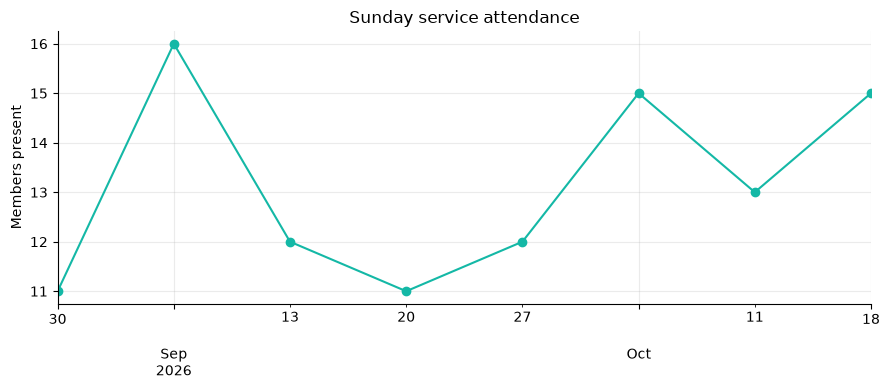

,event_id,event_name,event_date,present,rate_%
7,8,Sunday Service,2026-08-30,11,46.00
6,7,Sunday Service,2026-09-06,16,67.00
5,6,Sunday Service,2026-09-13,12,50.00
4,5,Sunday Service,2026-09-20,11,46.00
3,4,Sunday Service,2026-09-27,12,50.00
2,3,Sunday Service,2026-10-04,15,62.00
1,2,Sunday Service,2026-10-11,13,54.00
0,1,Sunday Service,2026-10-18,15,62.00


In [8]:
per_event = (
    attendance.groupby(['event_id', 'event_name', 'event_date'])
    .size().rename('present').reset_index()
    .sort_values('event_date')
)
per_event['rate_%'] = (per_event['present'] / len(members) * 100).round(0)

services = per_event[per_event['event_name'] == 'Sunday Service']
ax = services.plot(x='event_date', y='present', marker='o', color='#14b8a6', legend=False)
ax.set_title('Sunday service attendance')
ax.set_xlabel('')
ax.set_ylabel('Members present')
plt.tight_layout()
plt.show()
services.tail(8)

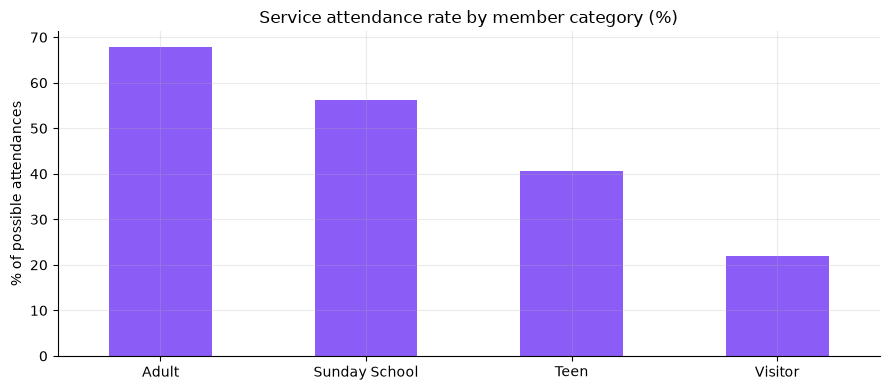

In [9]:
service_ids = set(services['event_id'])
present_by_category = attendance[attendance['event_id'].isin(service_ids)].groupby('category').size()
possible = members.groupby('category').size() * len(service_ids)
rate_by_category = (present_by_category / possible * 100).round(1).sort_values(ascending=False)

ax = rate_by_category.plot(kind='bar', color='#8b5cf6')
ax.set_title('Service attendance rate by member category (%)')
ax.set_xlabel('')
ax.set_ylabel('% of possible attendances')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Findings

The sentences below are generated from the data, so they stay correct if you load a different export.

In [10]:
best = services.loc[services['present'].idxmax()]
direction = 'rising' if slope > 0 else 'falling'
print(f"- Giving is {direction} by about P {abs(slope):,.0f} a month; next month is projected at P {next_month:,.0f}.")
print(f"- {regular} of {len(members)} members are regular givers, and the top 10 givers account for {by_member.head(10)['share_%'].sum():.0f}% of all giving.")
print(f"- Average Sunday service attendance is {services['present'].mean():.0f} members ({services['present'].mean() / len(members) * 100:.0f}% of the register).")
print(f"- The best-attended service was on {best['event_date']:%d %B %Y} with {int(best['present'])} members.")
print(f"- {rate_by_category.index[0]} members attend most often ({rate_by_category.iloc[0]}% of possible services).")

- Giving is rising by about P 196 a month; next month is projected at P 8,251.
- 13 of 24 members are regular givers, and the top 10 givers account for 64% of all giving.
- Average Sunday service attendance is 13 members (55% of the register).
- The best-attended service was on 06 September 2026 with 16 members.
- Adult members attend most often (67.9% of possible services).
